In [1]:
# Cell 2 - Imports
import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
# Cell 4 - Fetch GSE6044 from GEO
GSE60052 = GEOparse.get_GEO(geo='GSE60052', destdir="./data/raw/")

06-Mar-2026 12:05:12 DEBUG utils - Directory ./data/raw/ already exists. Skipping.
06-Mar-2026 12:05:12 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE60nnn/GSE60052/soft/GSE60052_family.soft.gz to ./data/raw/GSE60052_family.soft.gz
100%|██████████| 5.07k/5.07k [00:01<00:00, 3.29kB/s]
06-Mar-2026 12:05:17 DEBUG downloader - Size validation passed
06-Mar-2026 12:05:17 DEBUG downloader - Moving C:\Users\acer\AppData\Local\Temp\tmpdedyq5or to C:\Users\acer\SCLC Project\data\raw\GSE60052_family.soft.gz
06-Mar-2026 12:05:17 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE60nnn/GSE60052/soft/GSE60052_family.soft.gz
06-Mar-2026 12:05:17 INFO GEOparse - Parsing ./data/raw/GSE60052_family.soft.gz: 
06-Mar-2026 12:05:17 DEBUG GEOparse - DATABASE: GeoMiame
06-Mar-2026 12:05:17 DEBUG GEOparse - SERIES: GSE60052
06-Mar-2026 12:05:17 DEBUG GEOparse - PLATFORM: GPL11154
06-Mar-2026 12:05:17 DEBUG GEOparse - SAMPLE: GSM1464282
06-Mar-2026 12:05

In [5]:
print(GSE60052.metadata)

{'title': ['The RNAseq of 79 small cell lung cancer (sclc) and 7 normal control'], 'geo_accession': ['GSE60052'], 'status': ['Public on Feb 10 2016'], 'submission_date': ['Aug 04 2014'], 'last_update_date': ['May 15 2019'], 'pubmed_id': ['27093186'], 'summary': ['Even though small cell lung cancer (SCLC) has entered the age of broad genomic analysis, platinum-based chemotherapy remains the standard care for SCLC. Topotecan is the only approved agent for recurrent or progressive SCLC (1).  In the absence of well-defined genomic biomarkers, clinical efficacy signals in genomically distinct subsets of SCLC could have been missed. Serine/Arginine Splicing Factor 1 (SRSF1) is a member of SR protein family. The deleterious consequences of overexpression of the SRSF1 proto-oncogene in human cancers suggest that there are complex mechanisms and pathways underlying SRSF1-mediated transformation (2). Whole exome and transcriptome sequencing of primary tumor SCLC from 99 Chinese patients has iden

In [9]:
# Supplimentary matrix file

In [7]:
import urllib.request

url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE60nnn/GSE60052/suppl/GSE60052_79tumor.7normal.normalized.log2.data.Rda.tsv.gz"
urllib.request.urlretrieve(url, './data/raw/GSE60052_matrix.tsv.gz')
print("Download complete!")

Download complete!


In [11]:
import gzip
expr_matrix = pd.read_csv('./data/raw/GSE60052_matrix.tsv.gz', sep='\t', index_col=0)
print(expr_matrix.shape)
print(expr_matrix.head())

(51131, 86)
               11A        12A       13A        14A       15A        16A  \
gene                                                                      
5S_rRNA   0.000000   0.000000  0.000000   0.000000  0.000000   0.000000   
7SK      10.828115  11.803973  9.608837  10.419233  9.859020  11.048513   
A1BG      5.615586   7.337469  3.867909   1.772974  5.634852   5.493924   
A1CF      0.000000   0.000000  0.000000   0.000000  0.000000   0.000000   
A2LD1     1.952621   0.000000  3.924493   0.000000  0.000000   0.000000   

               17A        18A        20A       21A  ...   B12-738A   B12-814A  \
gene                                                ...                         
5S_rRNA   0.000000   5.402481   0.000000  0.000000  ...   0.000000   0.000000   
7SK      10.533401  10.255479  10.066778  9.608983  ...   8.502705   7.902092   
A1BG      5.964345   0.000000   4.151895  4.568568  ...   4.280728   4.824733   
A1CF      0.000000   3.080553   3.026364  1.109137  ...  

In [13]:
normal_samples = [col for col in expr_matrix.columns if 'normal' in col.lower()]
sclc_samples = [col for col in expr_matrix.columns if 'normal' not in col.lower()]
print(f"Normal samples: {len(normal_samples)}")
print(f"SCLC samples: {len(sclc_samples)}")

Normal samples: 7
SCLC samples: 79


In [15]:
# Create metadata
samples_of_interest = {col: 'Normal' if 'normal' in col.lower() else 'SCLC' 
                       for col in expr_matrix.columns}

metadata = pd.DataFrame({
    'sample_id': list(samples_of_interest.keys()),
    'group': list(samples_of_interest.values())
})
metadata = metadata.set_index('sample_id')
metadata.to_csv('./data/metadata/GSE60052_metadata.csv')
print(metadata['group'].value_counts())

group
SCLC      79
Normal     7
Name: count, dtype: int64


In [17]:
# Filter lowly expressed genes - keep genes expressed in at least 10% of samples
min_samples = int(0.1 * expr_matrix.shape[1])
expr_matrix_filtered = expr_matrix[(expr_matrix > 0).sum(axis=1) >= min_samples]

print(f"Genes before filtering: {expr_matrix.shape[0]}")
print(f"Genes after filtering: {expr_matrix_filtered.shape[0]}")
print(f"Genes removed: {expr_matrix.shape[0] - expr_matrix_filtered.shape[0]}")

Genes before filtering: 51131
Genes after filtering: 43035
Genes removed: 8096


In [19]:
expr_matrix_filtered.to_csv('./data/processed/GSE60052_expression_matrix.csv')

In [21]:
expr_matrix_filtered.index.name = 'Gene Symbol'

In [25]:
print(f"NA values: {expr_matrix_filtered.isna().sum().sum()}")
print(f"Duplicate gene symbols: {expr_matrix_filtered.index.duplicated().sum()}")
print(f"Shape: {expr_matrix_filtered.shape}")

NA values: 0
Duplicate gene symbols: 0
Shape: (43035, 86)


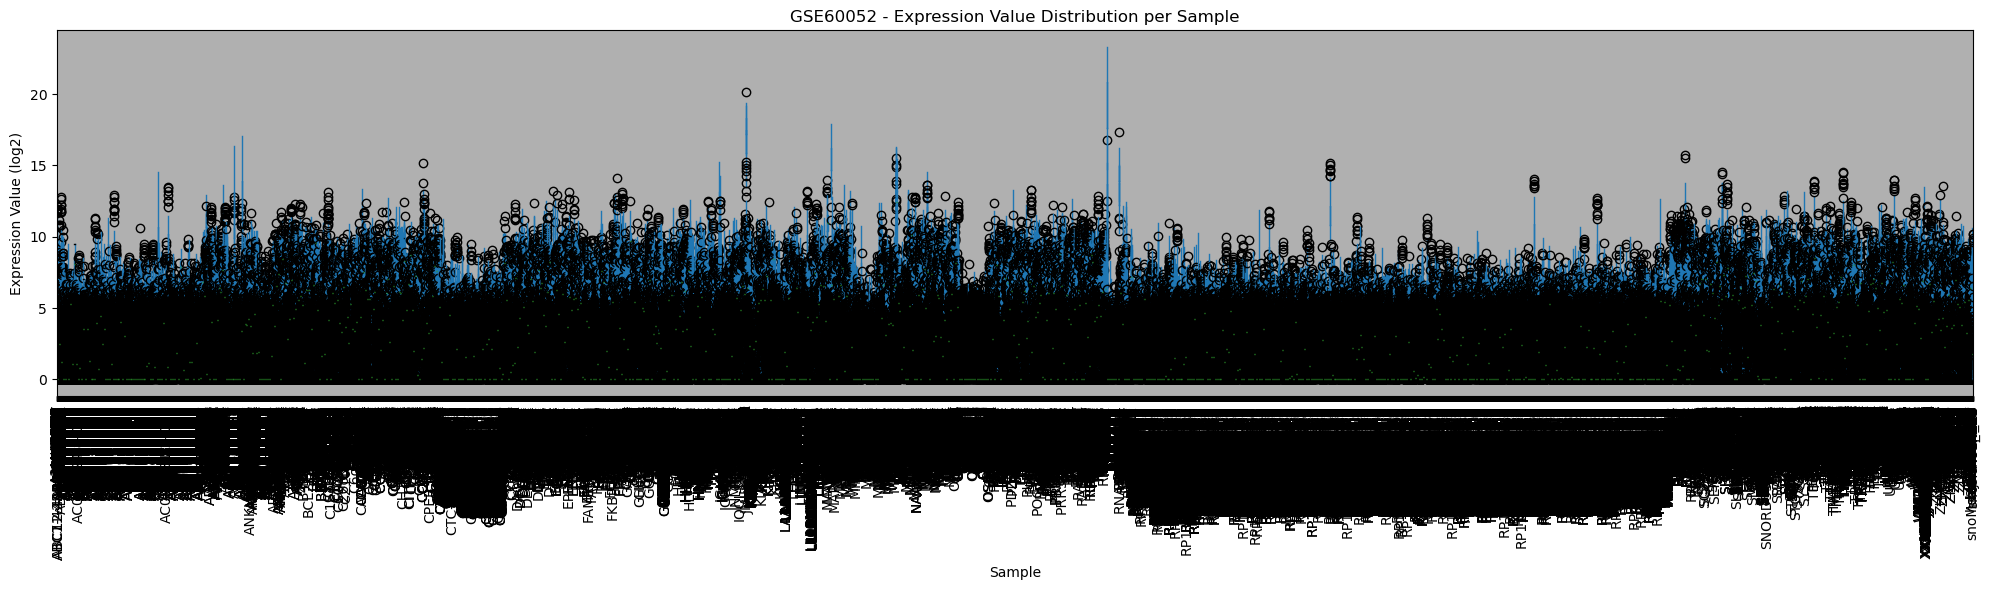

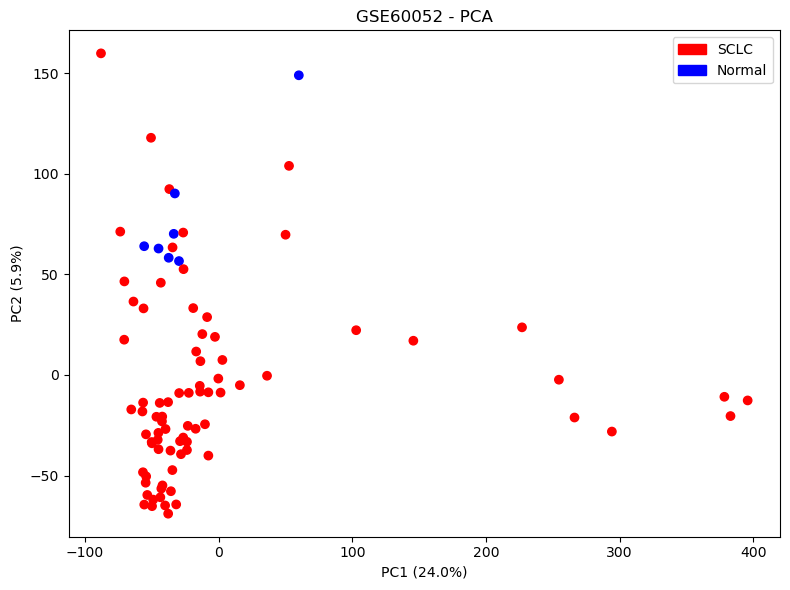

In [27]:
# Boxplot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 6))
expr_matrix_filtered.T.boxplot(figsize=(20, 6))
plt.title('GSE60052 - Expression Value Distribution per Sample')
plt.xlabel('Sample')
plt.ylabel('Expression Value (log2)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('./figures/GSE60052_boxplot.png')
plt.show()

# PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_matrix_filtered.T)
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(expr_scaled)

colors = ['blue' if 'normal' in s.lower() else 'red' for s in expr_matrix_filtered.columns]
plt.figure(figsize=(8, 6))
plt.scatter(pca_coords[:, 0], pca_coords[:, 1], c=colors)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('GSE60052 - PCA')
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color='red', label='SCLC'), Patch(color='blue', label='Normal')])
plt.tight_layout()
plt.savefig('./figures/GSE60052_PCA.png')
plt.show()

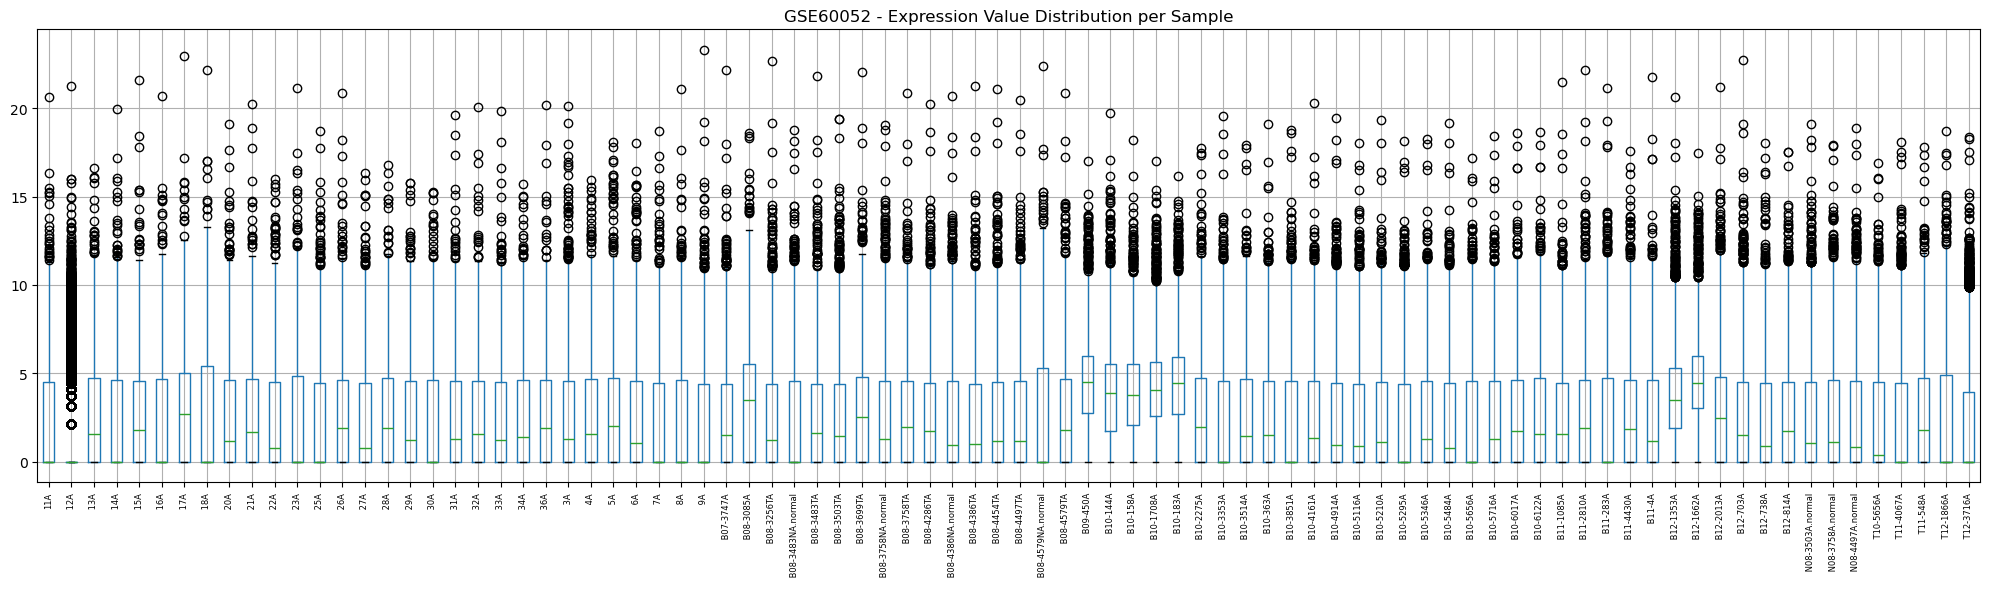

In [29]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 6))
expr_matrix_filtered.boxplot(figsize=(20, 6))
plt.xticks(rotation=90, fontsize=6)
plt.title('GSE60052 - Expression Value Distribution per Sample')
plt.tight_layout()
plt.savefig('./figures/GSE60052_boxplot.png', dpi=150)
plt.show()

In [41]:
# Load gene lists from processed microarray datasets
microarray_genes_30219 = pd.read_csv('./data/processed/GSE30219_expression_matrix.csv', index_col=0).index
microarray_genes_149507 = pd.read_csv('./data/processed/GSE149507_filtered_expression_matrix_final.csv', index_col=0).index

# Union of both microarray gene lists
protein_coding_proxy = microarray_genes_30219.union(microarray_genes_149507)
print(f"Proxy protein coding genes: {len(protein_coding_proxy)}")

# Filter RNA-seq matrix to these genes
expr_matrix_coding = expr_matrix_filtered[expr_matrix_filtered.index.isin(protein_coding_proxy)]
print(f"RNA-seq genes after filtering: {expr_matrix_coding.shape}")

Proxy protein coding genes: 24908
RNA-seq genes after filtering: (18362, 86)


In [43]:
expr_matrix_coding.index.name = 'Gene Symbol'
expr_matrix_coding.to_csv('./data/processed/GSE60052_expression_matrix.csv')

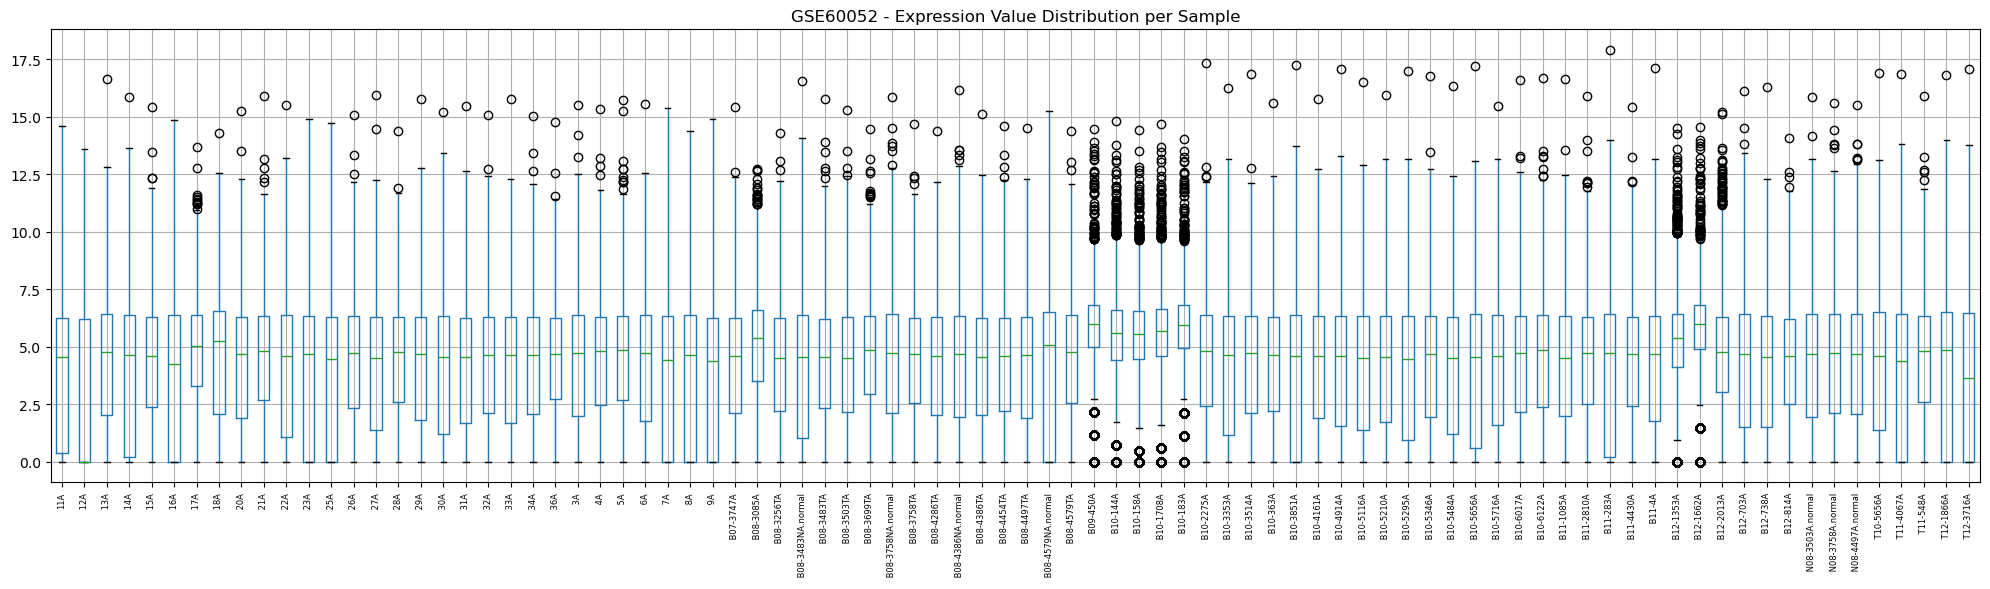

In [51]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 6))
expr_matrix_coding.boxplot(figsize=(20, 6))
plt.xticks(rotation=90, fontsize=6)
plt.title('GSE60052 - Expression Value Distribution per Sample')
plt.tight_layout()
plt.savefig('./figures/GSE60052_boxplot_coding.png', dpi=150)
plt.show()

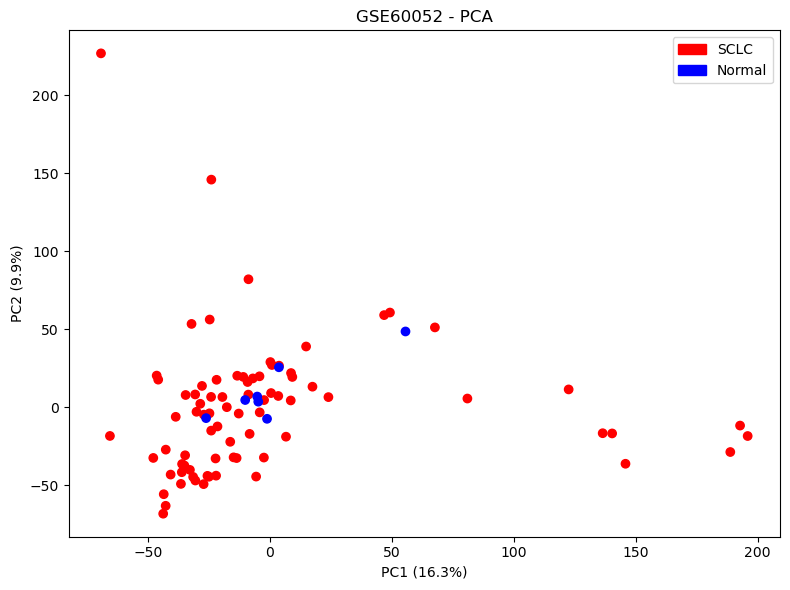

In [53]:
# PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_matrix_coding.T)
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(expr_scaled)

colors = ['blue' if 'normal' in s.lower() else 'red' for s in expr_matrix_coding.columns]
plt.figure(figsize=(8, 6))
plt.scatter(pca_coords[:, 0], pca_coords[:, 1], c=colors)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('GSE60052 - PCA')
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color='red', label='SCLC'), Patch(color='blue', label='Normal')])
plt.tight_layout()
plt.savefig('./figures/GSE60052_PCA_coding.png')
plt.show()

In [57]:
#Sanity check

print("Normal samples:")
for col in expr_matrix_coding.columns:
    if 'normal' in col.lower():
        print(f"  {col}")

print(f"\nSCLC samples: {sum(1 for col in expr_matrix_coding.columns if 'normal' not in col.lower())}")
print(f"Normal samples: {sum(1 for col in expr_matrix_coding.columns if 'normal' in col.lower())}")

# Cross check with metadata
print("\nMetadata group counts:")
print(metadata['group'].value_counts())

Normal samples:
   B08-3483NA.normal
   B08-3758NA.normal
   B08-4386NA.normal
   B08-4579NA.normal
   N08-3503A.normal
   N08-3758A.normal
   N08-4497A.normal

SCLC samples: 79
Normal samples: 7

Metadata group counts:
group
SCLC      79
Normal     7
Name: count, dtype: int64
